# Sparse wafer-map metrology, part 3: what to trust and where to measure
Parts 1 and 2 built the model (the average map plus a few PCA shapes, fitted to a few readings by
Bayesian linear regression) and showed that it beats every baseline on held-out lots. Part 3 asks
what a fab would need before using it:

1. **Which version of the model**, chosen on training lots only: 3, 4 or 5 shapes; whether the
   prior knows that the level and the shapes move together; whether it uses the wafer's position in
   its lot; whether neighbouring sites share their leftover.
2. **Ranges that hold.** Part 2's 90% ranges held only 86% of the hidden depths. Why, and the fix,
   with the width set on training lots only.
3. **The input check's threshold**, as a function of how many sites are measured.
4. **A flag for wafers unlike past ones**, its false-alarm rate, and what extra sites buy on a
   flagged wafer.
5. **Where to measure.** Sites chosen by the model, against the routine 9 and against random sites.

**The rule throughout:** every choice (model version, range width, thresholds, sites) is made on the
training lots of each fold, by hiding one training lot at a time (the *inner split*). The held-out
lot is used once, at the end, to score the result. One caveat: all 10 lots were looked at in parts 1
and 2, so the choice of *what* to fix was informed by every lot. The nested choices keep the numbers
honest, but not the choice of questions.

**To run:** in Colab, Runtime → Run all. The data loads from this repository's `data/` folder (or
straight from GitHub). Runs in about 3 minutes.

Data: Langer et al., BOSCH plasma-etching dataset, Zenodo 2025, doi:10.5281/zenodo.17122442 (CC BY 4.0).

## 0. Setup: data, the bad-reading screen, part 1's model and the two history-based rivals
Copied unchanged from notebook 02 so that this notebook runs on its own. Notebooks 01 and 02 explain
each piece.

In [1]:
# Tools: numpy for arrays, pandas for tables, matplotlib for plots
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Where the data files are: the repository's data/ folder, or GitHub itself (e.g. in Colab)
DATA_URL = 'https://raw.githubusercontent.com/arifulRPI/sparse-wafer-metrology/main/data/'
def data_path(name):
    for folder in ['data', '../data', '.']:
        if os.path.exists(os.path.join(folder, name)):
            return os.path.join(folder, name)
    return DATA_URL + name

# Where figures go: the repository's figures/ folder if we're inside it, else the current folder
FIG_DIR = next((d for d in ['figures', '../figures'] if os.path.isdir(d)), '.')

full = pd.read_csv(data_path('Si_Oxide_etch_89_points.csv'))  # 89 sites per wafer (Feb 2025, KLA Tencor P-17)
rout = pd.read_csv(data_path('Si_Oxide_etch_9_points.csv'))   # 9 routine sites per wafer (etch day, Veeco Dektak 8)
TARGET = 'stepheight'      # main target; silicon etch depth is repeated in section 8

In [2]:
# The wafer x site tables: one row per wafer, one column per site
full['site'] = list(zip(full.X // 1000, full.Y // 1000))          # site = (x, y) in mm
sites = sorted(full.site.unique(), key=lambda s: (-s[1], s[0]))    # fixed order: top row first
wafers = full[['experiment_key', 'lot_number', 'wafer_number']].drop_duplicates()
wafers = wafers.sort_values(['lot_number', 'wafer_number']).reset_index(drop=True)
def table(column):
    """88 x 89 array of one measured quantity (µm), rows in lot/wafer order."""
    T = full.pivot(index='experiment_key', columns='site', values=column)
    return T.loc[wafers.experiment_key, sites].to_numpy()
Y = table(TARGET)                                                  # step height
Ysi = table('si_etch')                                             # silicon etch depth (step height minus oxide)
lot = wafers.lot_number.to_numpy()
lots = np.unique(lot)
xy = np.array(sites, dtype=float)                                  # site coordinates (mm)
r = np.hypot(xy[:, 0], xy[:, 1])                                   # site radius (mm)
inner = r <= 76.5                                                  # 49 inner sites, 40 outer
r9 = rout[['loc_id', 'X', 'Y']].drop_duplicates()
routine = [sites.index((x // 1000, y // 1000)) for x, y in zip(r9.X, r9.Y)]   # the routine 9 on the grid
rout = rout.dropna(subset=['experiment_key'])                      # drop rows with no wafer label
print('table:', Y.shape, '| inner/outer sites:', inner.sum(), (~inner).sum(), '| routine sites:', len(routine))

table: (88, 89) | inner/outer sites: 49 40 | routine sites: 9


In [3]:
# The bad-reading screen (part 1, section 3): compare each reading with the median of its
# neighbours, after removing the wafer's level and the typical map. Used on training wafers only.
dist = np.hypot(xy[:, None, 0] - xy[None, :, 0], xy[:, None, 1] - xy[None, :, 1])  # site-to-site distances (mm)
nbrs = [np.where((dist[s] > 0) & (dist[s] < 28.5))[0] for s in range(89)]      # touching sites
same_ring = [np.argsort(np.where((np.abs(r - r[s]) <= 10) & (dist[s] > 0), dist[s], np.inf))[:2]
             for s in range(89)]                                                # replacement sites

def screen_scores(M, ref):
    """Score every reading in M; 'typical' is learned from the reference maps ref (training wafers)."""
    typical = np.median(ref - np.median(ref, axis=1, keepdims=True), axis=0)   # typical map shape
    def gap(A):
        dev = A - np.median(A, axis=1, keepdims=True) - typical                # each wafer's own deviation
        return np.stack([dev[:, s] - np.median(dev[:, nbrs[s]], axis=1) for s in range(89)], axis=1)
    g, g_ref = gap(M), gap(ref)
    centre = np.median(g_ref, axis=0)                                  # usual gap at each site
    spread = 1.4826 * np.median(np.abs(g_ref - centre), axis=0)        # MAD, scaled to match a std
    return (g - centre) / spread, g - centre                           # score, and size in µm

def screen(M, ref, threshold):
    """Flag and replace readings one at a time, worst first, until none exceed the threshold."""
    M = M.copy()
    flagged = []
    done = np.zeros(M.shape, bool)
    while True:
        z, size = screen_scores(M, ref)
        z[done] = 0                                                    # each reading is flagged at most once
        w, s = np.unravel_index(np.argmax(np.abs(z)), z.shape)        # the most unusual reading left
        if abs(z[w, s]) <= threshold:
            return M, flagged
        flagged.append((w, s, M[w, s], z[w, s], size[w, s]))
        M[w, s] = M[w, same_ring[s]].mean()                          # replace with two same-ring sites
        done[w, s] = True

THRESHOLD = 30
def suspects_of(M):
    """Where the screen flags a reading on all wafers: used only to decide what to score, never to fit."""
    return [(w, s) for w, s, *_ in screen(M, M, THRESHOLD)[1]]
suspect = suspects_of(Y)
for w, s in suspect:
    print('suspect reading: lot %d wafer %d, site %s' % (lot[w], wafers.wafer_number[w], sites[s]))

suspect reading: lot 6 wafer 7, site (-76, -38)
suspect reading: lot 3 wafer 2, site (95, -19)


In [4]:
# The model (part 1, section 5): depth = average map + level + b1*shape1 + ... + b4*shape4 + leftover
K = 4   # number of shapes, fixed before testing

def learn(M, K):
    """Learn everything the fit needs from training maps M (rows = wafers)."""
    level = M.mean(axis=1)                                  # each wafer's mean depth
    dev = M - level[:, None]
    avg = dev.mean(axis=0)                                  # average map (shape only)
    D = dev - avg
    Vt = np.linalg.svd(D, full_matrices=False)[2][:K]       # the K shapes
    b = D @ Vt.T                                            # how much of each shape every wafer has
    leftover = D - b @ Vt                                   # what the shapes miss
    return dict(avg=avg, shapes=Vt,
                prior_mean=np.r_[level.mean(), np.zeros(K)],              # typical level, zero shapes
                prior_var=np.r_[level.var(ddof=1), b.var(axis=0, ddof=1)],
                noise_var=np.mean(leftover**2, axis=0))                   # leftover spread at each site

def fit(m, idx, y_meas, prior_mean=None):
    """Posterior for (level, b1..bK) from readings y_meas (wafers x k) at sites idx; full maps + 90% ranges.
    prior_mean can be one row per wafer (section 9); by default it is the same for every wafer."""
    X_all = np.column_stack([np.ones(89), m['shapes'].T])      # 89 x (K+1): level column + shapes
    X = X_all[idx]                                             # rows for the measured sites
    w = 1 / m['noise_var'][idx]                                # trust each reading by its leftover spread
    P0 = 1 / m['prior_var']                                    # prior strength
    mu0 = m['prior_mean'][None, :] if prior_mean is None else prior_mean
    cov = np.linalg.inv(np.diag(P0) + X.T @ (w[:, None] * X))  # posterior spread of the coefficients
    rhs = (P0[None, :] * mu0).T + X.T @ (w[:, None] * (y_meas - m['avg'][idx]).T)
    coef = cov @ rhs                                           # posterior mean, one column per wafer
    pred = m['avg'][None, :] + (X_all @ coef).T                # predicted full maps
    sd = np.sqrt(np.sum((X_all @ cov) * X_all, axis=1) + m['noise_var'])   # prediction spread per site
    return pred, 1.645 * sd                                    # 90% range = pred ± 1.645 sd

In [5]:
# Which sites can be scored: False at the suspect readings (scores B and C)
def valid_mask(suspects, shape=Y.shape):
    v = np.ones(shape, bool)
    for w, s in suspects:
        v[w, s] = False
    return v
valid = valid_mask(suspect)

In [6]:
# Rival B2's Gaussian process, used here only inside rival A+GP (notebook 02, section 2)
# Rival B2: a Gaussian process (squared-exponential correlation between sites)
D2 = dist ** 2
def gp_learn(Ytr):
    """Smoothness (length scale) and noise share chosen by maximum likelihood on training full maps."""
    Z = Ytr - Ytr.mean(axis=1, keepdims=True)
    N = len(Z)
    best = None
    for ell in [20, 30, 40, 60, 80, 100, 130, 160, 200, 260]:            # length scale (mm)
        Rm = np.exp(-D2 / (2 * ell ** 2))
        for ratio in [0.01, 0.03, 0.1, 0.3]:                             # noise relative to signal
            C = Rm + ratio ** 2 * np.eye(89)
            Ci = np.linalg.inv(C)
            logdet = np.linalg.slogdet(C)[1]
            s2 = np.einsum('wi,ij,wj->', Z, Ci, Z) / (N * 89)             # best overall variance
            ll = -0.5 * (N * 89 * np.log(s2) + N * logdet)                # log-likelihood (up to a constant)
            if best is None or ll > best[0]:
                best = (ll, ell, ratio)
    return dict(ell=best[1], ratio=best[2])

def gp_fit(g, idx, yk):
    """GP interpolation of the readings yk at sites idx, around a constant level fitted to them."""
    Rm = np.exp(-D2 / (2 * g['ell'] ** 2))
    C = Rm[np.ix_(idx, idx)] + g['ratio'] ** 2 * np.eye(len(idx))
    Ci = np.linalg.inv(C)
    one = np.ones(len(idx))
    mu = (yk @ Ci @ one) / (one @ Ci @ one)                              # constant level (generalised least squares)
    return mu[:, None] + (Rm[:, idx] @ Ci @ (yk - mu[:, None]).T).T

# Rival A+GP: the average map, plus a GP on the wafer's own deviation from it
def gpa_learn(Ytr, m_a):
    D = Ytr - Ytr.mean(axis=1, keepdims=True) - m_a['avg']             # training deviations from the average map
    return gp_learn(D) | {'avg': m_a['avg']}

def gpa_fit(g, idx, yk):
    return g['avg'][None, :] + gp_fit(g, idx, yk - g['avg'][idx][None, :])

In [7]:
# Part 2's input check (notebook 02, section 3), kept to show that section 1 reproduces it
T_CHECK = 6.0

def loo_z(m, idx, yk):
    """How far each measured reading is from what the other readings predict, in predicted spreads."""
    z = np.zeros(yk.shape)
    for j in range(len(idx)):
        rest = np.delete(np.arange(len(idx)), j)
        pred, half = fit(m, idx[rest], yk[:, rest])
        z[:, j] = (yk[:, j] - pred[:, idx[j]]) / (half[idx[j]] / 1.645)
    return np.abs(z)

def keep_mask(m, idx, yk, use_check):
    """Which measured readings each wafer keeps: drops at most the single worst one."""
    keep = np.ones(yk.shape, bool)
    if use_check and len(idx) > 2:
        z = loo_z(m, idx, yk)
        j = np.argmax(z, axis=1)
        bad = z[np.arange(len(yk)), j] > T_CHECK
        keep[np.where(bad)[0], j[bad]] = False
    return keep

In [8]:
# The same random layouts as parts 1 and 2 (same seed, same order), plus 20-site layouts for the check
ks = list(range(3, 14))
rng = np.random.default_rng(0)
layouts = {k: [rng.choice(89, k, replace=False) for _ in range(200)] for k in ks}
layouts['routine 9'] = [np.array(routine)]
rng20 = np.random.default_rng(1)
layouts[20] = [rng20.choice(89, 20, replace=False) for _ in range(200)]
rng_extra = np.random.default_rng(2)                               # other sizes, used only on the inner split
for k in [2] + list(range(14, 20)):
    layouts[k] = [rng_extra.choice(89, k, replace=False) for _ in range(40)]
pos = wafers.wafer_number.to_numpy().astype(float)                 # position of each wafer in its lot (1-10)

## 1. The model as a statement about how the 89 depths move together
Part 1's model says: depth = average map + level + amounts × shapes + leftover. The level and the
amounts vary from wafer to wafer with spreads learned from past wafers (the prior); the leftover
varies from site to site. Together this says how the 89 depths of a new wafer vary *together*:
their typical values (a mean map) and how each pair of sites moves together (an 89 × 89 covariance).

Predicting the hidden sites from the measured ones is then one step: given the readings, what do the
other sites do? For depths that vary together like this (jointly Gaussian), the answer is the usual
regression formula on the covariance. It gives exactly part 1's predictions and ranges (checked
below), and it makes the variants of this part easy to write:

- **full prior:** the prior knows that level and shape amounts move together (part 1's prior treated
  them as unrelated). Across past wafers, the level and the edge-ring amount correlate at 0.88.
- **position:** the prior's centre moves with the wafer's position in its lot (part 2, section 9).
- **correlated leftover:** neighbouring sites share part of their leftover, fading with distance.
  Part 1 found that many inner readings made the edge *worse*, probably because the model treated
  their leftovers as independent and trusted them too much.
- **K:** 3, 4 or 5 shapes.

In [9]:
SQ = dist ** 2                                                     # squared site-to-site distances

def leftover_corr(U):
    """How much neighbouring sites share their leftover: (1 - nug) * exp(-d^2 / 2 ell^2) between sites,
    1 on the diagonal. ell and nug are chosen by maximum likelihood on the training leftovers U."""
    best = None
    for ell in [10, 15, 20, 25, 30, 40, 50]:                      # how fast sharing fades (mm)
        E = np.exp(-SQ / (2 * ell ** 2))
        for nug in [0.05, 0.1, 0.2, 0.3, 0.5, 0.7]:               # share that is each site's own
            R = (1 - nug) * E + nug * np.eye(89)
            ll = -0.5 * (len(U) * np.linalg.slogdet(R)[1] + np.einsum('wi,ij,wj->', U, np.linalg.inv(R), U))
            if best is None or ll > best[0]:
                best = (ll, R)
    return best[1]

def coefficients(M, m):
    """Each wafer's level and shape amounts, by least squares on all 89 sites."""
    level = M.mean(axis=1)                                         # the shapes average to zero, so level = mean
    return np.column_stack([level, (M - level[:, None] - m['avg']) @ m['shapes'].T])

def learn_model(M, posM, cfg):
    """Learn a model version cfg from training maps M (rows = wafers) at positions posM."""
    K = cfg['K']
    level = M.mean(axis=1)
    dev = M - level[:, None]
    avg = dev.mean(axis=0)                                         # average map
    D = dev - avg
    shapes = np.linalg.svd(D, full_matrices=False)[2][:K]          # the K shapes (PCA)
    m = dict(cfg=cfg, avg=avg, shapes=shapes, X=np.column_stack([np.ones(89), shapes.T]))
    c = coefficients(M, m)                                         # every training wafer's level and amounts
    if cfg['position']:                                            # prior centre: a straight line in position
        P = np.column_stack([np.ones(len(M)), posM])
        m['B'] = np.linalg.lstsq(P, c, rcond=None)[0]
        dc, dof = c - P @ m['B'], 2
    else:                                                          # prior centre: the average wafer
        m['B'] = c.mean(axis=0)[None, :]
        dc, dof = c - m['B'], 1
    C0 = dc.T @ dc / (len(M) - dof)                                # prior covariance of level and amounts
    m['C0'] = C0 if cfg['prior'] == 'full' else np.diag(np.diag(C0))
    leftover = D - (D @ shapes.T) @ shapes                         # what the shapes miss
    m['s'] = np.sqrt(np.mean(leftover ** 2, axis=0))               # leftover spread at each site
    m['R'] = leftover_corr(leftover / m['s']) if cfg['leftover'] == 'correlated' else np.eye(89)
    m['S'] = m['X'] @ m['C0'] @ m['X'].T + m['s'][:, None] * m['R'] * m['s'][None, :]   # 89 x 89 covariance
    return m

def prior_mean(m, posw):
    """Prior centre of (level, amounts) for wafers at positions posw."""
    if m['cfg']['position']:
        return np.column_stack([np.ones(len(posw)), posw]) @ m['B']
    return np.repeat(m['B'], len(posw), axis=0)

def predict(m, idx, yk, posw):
    """Predicted full maps from readings yk (wafers x k) at sites idx, and the spread (SD) at each site."""
    mu = m['avg'][None, :] + prior_mean(m, posw) @ m['X'].T        # typical map for each wafer
    S = m['S']
    if len(idx) == 0:
        return mu, np.sqrt(np.diag(S))
    A = np.linalg.solve(S[np.ix_(idx, idx)], S[idx, :])            # how each site follows the measured ones
    pred = mu + (yk - mu[:, idx]) @ A
    sd = np.sqrt(np.maximum(np.diag(S) - np.sum(S[idx, :] * A, axis=0), 0))
    return pred, sd                                                # 90% range = pred ± 1.645 sd

def surprise(m, idx, yk, posw):
    """Three ways the readings can surprise the model:
    z  - each reading against what the other readings predict (leave-one-out), in predicted spreads;
    d2 - all readings together against what is usual (0 to about k for a usual wafer);
    amounts - the part of d2 that comes from shape amounts far from usual."""
    mu = m['avg'][None, :] + prior_mean(m, posw) @ m['X'].T
    r = yk - mu[:, idx]                                            # readings minus the typical map
    P = np.linalg.inv(m['S'][np.ix_(idx, idx)])
    Pr = r @ P
    z = np.abs(Pr) / np.sqrt(np.diag(P))                           # leave-one-out z, in closed form
    d2 = np.sum(Pr * r, axis=1)
    dc = Pr @ (m['X'][idx] @ m['C0'])                              # fitted level and amounts minus the prior centre
    amounts = np.sum((dc @ np.linalg.pinv(m['C0'])) * dc, axis=1)
    return z, d2, amounts

In [10]:
# Check: with part 1's choices (diagonal prior, no position, 4 shapes, independent leftover)
# this gives part 1's predictions, ranges and leave-one-out z, to rounding error.
PART1 = dict(K=4, prior='diag', position=False, leftover='independent')
tr, te = lot != 3, np.where(lot == 3)[0]
Ytr, _ = screen(Y[tr], Y[tr], THRESHOLD)
m_old, m_new = learn(Ytr, K), learn_model(Ytr, pos[tr], PART1)
for idx in [layouts[5][0], np.array(routine)]:
    hid = np.ones(89, bool); hid[idx] = False
    p0, h0 = fit(m_old, idx, Y[te][:, idx])
    p1, s1 = predict(m_new, idx, Y[te][:, idx], pos[te])
    print('largest difference at hidden sites: prediction %.1e µm, range %.1e µm, z %.1e'
          % (np.abs(p0 - p1)[:, hid].max(), np.abs(h0 - 1.645 * s1)[hid].max(),
             np.abs(loo_z(m_old, idx, Y[te][:, idx]) - surprise(m_new, idx, Y[te][:, idx], pos[te])[0]).max()))

largest difference at hidden sites: prediction 4.1e-13 µm, range 4.8e-15 µm, z 5.1e-12
largest difference at hidden sites: prediction 1.4e-12 µm, range 6.1e-15 µm, z 9.8e-12


## 2. Settle the model on training lots only
24 versions: 3, 4 or 5 shapes × diagonal or full prior × with or without position × independent or
correlated leftover. In each fold, every version is scored on the inner split: hide one training lot,
learn from the other eight, predict the hidden lot's clean maps from 40 random layouts of 3, 5 and 9
sites and from the routine 9. The score is the RMS error at hidden sites, averaged on a log scale over
those four, so that each number of sites counts equally.

**The rule:** take the simplest version within 1% of the best. Simplest means fewest additions to
part 1 (full prior, position, correlated leftover), then fewest shapes. A gain under 1% is within
what 9 lots can resolve, and every addition must earn its place.

In [11]:
CFGS = [dict(K=k, prior=p, position=q, leftover=l) for l in ['independent', 'correlated']
        for p in ['diag', 'full'] for q in [False, True] for k in [3, 4, 5]]
def cfg_name(c):
    return '%d shapes, %s prior, %s, %s leftover' % (c['K'], c['prior'], 'position' if c['position'] else 'no position', c['leftover'])
def additions(c):
    return (c['prior'] == 'full') + c['position'] + (c['leftover'] == 'correlated')
LAY4 = [3, 5, 9, 'routine 9']

def inner_layouts(k):
    """The layouts used on the inner split: 40 of each random size, or the routine 9."""
    return layouts[k] if k == 'routine 9' else layouts[k][:40]

def choose_model(M, lM, pM):
    """Score every version on the inner split of the training maps M; return the chosen one and the scores."""
    scores = []
    for cfg in CFGS:
        sse = {lay: np.zeros(2) for lay in LAY4}
        for l in np.unique(lM):                                    # hide one training lot at a time
            o = lM != l
            mo = learn_model(M[o], pM[o], cfg)
            for lay in LAY4:
                for idx in inner_layouts(lay):
                    p = predict(mo, idx, M[~o][:, idx], pM[~o])[0]
                    hid = np.ones(89, bool); hid[idx] = False
                    sse[lay] += [((p - M[~o])[:, hid] ** 2).sum(), (~o).sum() * hid.sum()]
        scores.append(np.exp(np.mean([np.log(np.sqrt(a[0] / a[1])) for a in sse.values()])))
    scores = np.array(scores)
    near = np.where(scores <= 1.01 * scores.min())[0]              # within 1% of the best
    best = min(near, key=lambda i: (additions(CFGS[i]), CFGS[i]['K'], scores[i]))
    return CFGS[best], scores

t0 = time.time()
TRAIN, CHOICE = {}, {}
for L in lots:
    tr = lot != L
    assert L not in set(lot[tr])                                   # leakage check: the test lot never trains
    Ytr, _ = screen(Y[tr], Y[tr], THRESHOLD)                       # screen the training wafers only
    TRAIN[L] = (Ytr, lot[tr], pos[tr])
    CHOICE[L] = choose_model(*TRAIN[L])
    print('test lot %2d: %s' % (L, cfg_name(CHOICE[L][0])))
print('%.0f s' % (time.time() - t0))

test lot  1: 5 shapes, full prior, no position, independent leftover


test lot  2: 5 shapes, full prior, no position, independent leftover


test lot  3: 5 shapes, full prior, no position, independent leftover


test lot  4: 5 shapes, full prior, no position, independent leftover


test lot  5: 5 shapes, full prior, no position, independent leftover


test lot  6: 5 shapes, full prior, no position, independent leftover


test lot  7: 5 shapes, full prior, no position, independent leftover


test lot  8: 4 shapes, full prior, position, independent leftover


test lot  9: 5 shapes, full prior, no position, independent leftover


test lot 10: 5 shapes, full prior, no position, independent leftover
50 s


In [12]:
# Inner-split score of every version, averaged over the 10 folds (µm)
table = pd.DataFrame([dict(shapes=c['K'], prior=c['prior'], position=c['position'], leftover=c['leftover'],
                           score=np.mean([CHOICE[L][1][i] for L in lots])) for i, c in enumerate(CFGS)])
print(table.pivot_table(index=['leftover', 'prior', 'position'], columns='shapes', values='score').round(4).to_string())

shapes                           3       4       5
leftover    prior position                        
correlated  diag  False     0.0912  0.0903  0.0854
                  True      0.0878  0.0870  0.0829
            full  False     0.0878  0.0868  0.0813
                  True      0.0880  0.0870  0.0816
independent diag  False     0.0913  0.0905  0.0857
                  True      0.0880  0.0873  0.0831
            full  False     0.0880  0.0870  0.0815
                  True      0.0882  0.0872  0.0818


**What the inner split chose.** In 9 of 10 folds: 5 shapes and the full prior, with no position and
independent leftovers. In the fold that holds out lot 8 it chose 4 shapes, the full prior and position.

- **The full prior is the big gain** (about 4–5% on the score above, 15% at 3 sites). When the readings
  pin down the level, the full prior also moves the edge ring, because the two move together.
- **Position adds nothing once the prior is full.** Position predicted the drift within a lot (deeper
  and more ring-shaped early on). The full prior gets the same from the readings: a deep wafer is a
  ring-shaped one.
- **A fifth shape helps** by about 5–6%, with either prior. Parts 1 and 2 kept 4, fixed in advance, and
  part 2 saw 5 do slightly better at 5 sites.
- **Correlated leftover gains under 1%** at these numbers of sites, so the rule leaves it out. It does
  help in the case that motivated it, many inner readings (section 9).

## 3. Everything else, learned on the training lots of each fold
With the model version fixed, the inner split is used again (hide one training lot at a time, learn
from the rest, and look at the hidden lot's clean maps) to learn four more things:

1. **How far off the 90% ranges are.** Each miss at a hidden site, divided by its predicted spread,
   should exceed 1.645 only 10% of the time. *Version 1* widens the ranges by one factor, so that 90%
   of the inner-split misses fall inside. *Version 2* first measures, on the lot the model did not
   learn from, how much further the level, the amounts and the leftover stray than the model expects,
   puts that into the model, and then sets one factor on what is left. Version 2 needs a second inner
   split inside each inner fold, so it is slower.
2. **The input check's threshold** for each number of sites: the leave-one-out z that the largest of a
   clean wafer's readings exceeds only 1% of the time. One clean wafer in 100 then has a good reading
   questioned (a re-measurement).
3. **The flag's threshold** for each number of sites: the surprise d2 that only 5% of training wafers
   exceed. One usual wafer in 20 would be sent for more sites.
4. **Where to measure** (section 8): sites added one at a time, each time the one that most lowers the
   model's predicted error of the map, summed over all 89 sites.

In [13]:
CHECK_RATE, FLAG_RATE = 0.01, 0.05                                 # policy: 1% of clean wafers re-measured, 5% flagged
KS_CHECK = list(range(2, 21))                                      # thresholds for 2 to 20 readings

def stray(M, lM, pM, cfg):
    """Version 2: on lots the model did not learn from, how far the level and amounts (a) and the
    leftover (b) stray, as multiples of the variance the model expects."""
    sa = na = sb = nb = 0.0
    for l in np.unique(lM):
        o = lM != l
        mo = learn_model(M[o], pM[o], cfg)
        c = coefficients(M[~o], mo)
        dc = c - prior_mean(mo, pM[~o])
        sa += np.sum((dc @ np.linalg.inv(mo['C0'])) * dc)
        na += dc.size
        left = M[~o] - mo['avg'] - c @ mo['X'].T
        sb += np.sum(left ** 2 / mo['s'] ** 2)
        nb += len(left) * (89 - mo['X'].shape[1])
    return sa / na, sb / nb

def learn_v2(M, lM, pM, cfg):
    """The model with the stray from version 2 put into it."""
    m = learn_model(M, pM, cfg)
    a, b = stray(M, lM, pM, cfg)
    m['C0'], m['s'], m['ab'] = a * m['C0'], np.sqrt(b) * m['s'], (a, b)
    m['S'] = m['X'] @ m['C0'] @ m['X'].T + m['s'][:, None] * m['R'] * m['s'][None, :]
    return m

def inner_split(M, lM, pM, cfg, version=1):
    """Hide one training lot at a time and collect: standardized misses at hidden sites (for the range
    factor), each clean wafer's largest leave-one-out z (check threshold), and d2 (flag threshold)."""
    misses, zmax, d2 = [], {k: [] for k in KS_CHECK}, {k: [] for k in KS_CHECK}
    for l in np.unique(lM):
        o = lM != l
        mo = learn_model(M[o], pM[o], cfg) if version == 1 else learn_v2(M[o], lM[o], pM[o], cfg)
        Mt, pt = M[~o], pM[~o]
        for k in LAY4:
            for idx in inner_layouts(k):
                p, sd = predict(mo, idx, Mt[:, idx], pt)
                hid = np.ones(89, bool); hid[idx] = False
                misses.append((len(idx), np.abs(p - Mt)[:, hid] / sd[hid], surprise(mo, idx, Mt[:, idx], pt)[1]))
        if version == 1:
            for k in KS_CHECK:
                for idx in inner_layouts(k):
                    z, dd, _ = surprise(mo, idx, Mt[:, idx], pt)
                    zmax[k] += list(z.max(axis=1))
                    d2[k] += list(dd)
    return misses, zmax, d2

def widening(misses, keep=None):
    """The factor that puts 90% of the standardized misses inside the range."""
    z = np.concatenate([zz[keep(k, dd)] if keep else zz for k, zz, dd in misses], axis=None)
    return np.quantile(z, 0.90) / 1.645

def map_error(m, idx):
    """The model's predicted error of the map (pattern part), summed over the 89 sites, after measuring idx."""
    X, w = m['X'], 1 / m['s'][idx] ** 2
    cov = np.linalg.inv(np.linalg.inv(m['C0']) + X[idx].T @ (w[:, None] * X[idx]))
    return np.sum((X @ cov) * X)

def choose_sites(m, n):
    """Add sites one at a time, each time the one that most lowers the predicted map error."""
    chosen = []
    for _ in range(n):
        err = [map_error(m, chosen + [s]) if s not in chosen else np.inf for s in range(89)]
        chosen.append(int(np.argmin(err)))
    return np.array(chosen)

def prepare(L):
    """Everything used to test lot L, learned from its training lots only."""
    Ytr, lM, pM = TRAIN[L]
    cfg = CHOICE[L][0]
    P = dict(cfg=cfg, m=learn_model(Ytr, pM, cfg), m2=learn_v2(Ytr, lM, pM, cfg))
    misses, zmax, d2 = inner_split(Ytr, lM, pM, cfg)
    P['T'] = {k: np.quantile(v, 1 - CHECK_RATE) for k, v in zmax.items()}            # check thresholds
    P['TF'] = {k: np.quantile(v, 1 - FLAG_RATE) for k, v in d2.items()}               # flag thresholds
    P['TFq'] = {k: {q: np.quantile(v, q) for q in [0.8, 0.85, 0.9, 0.95, 0.99]} for k, v in d2.items()}
    P['f1'] = widening(misses)                                                        # version 1
    P['f2'] = widening(inner_split(Ytr, lM, pM, cfg, version=2)[0])                   # version 2
    P['f_pass'] = widening(misses, keep=lambda k, dd: dd <= P['TF'][k])               # wafers the flag passes
    P['sites'] = choose_sites(P['m'], 20)
    P['rival A'] = learn(Ytr, 0)
    P['rival A+GP'] = gpa_learn(Ytr, P['rival A'])
    return P

t0 = time.time()
PREP = {L: prepare(L) for L in lots}
print('%.0f s' % (time.time() - t0))
print(pd.DataFrame({L: {'range factor, version 1': P['f1'], 'version 2 stray a (amounts)': P['m2']['ab'][0],
                        'version 2 stray b (leftover)': P['m2']['ab'][1], 'range factor after stray, version 2': P['f2'],
                        'range factor, wafers the flag passes': P['f_pass'],
                        'check threshold, 5 sites': P['T'][5], 'flag threshold, 5 sites': P['TF'][5]}
                    for L, P in PREP.items()}).round(2).to_string())

9 s
                                         1      2      3      4      5      6      7      8      9      10
range factor, version 1                1.00   1.23   1.26   1.28   1.22   1.24   1.19   1.18   1.25   1.20
version 2 stray a (amounts)            0.95   1.80   1.89   1.75   1.75   1.84   1.68   1.98   2.04   1.74
version 2 stray b (leftover)           2.27   2.69   2.70   2.80   2.69   2.20   2.70   2.24   2.57   2.45
range factor after stray, version 2    0.76   0.86   0.86   0.87   0.85   0.89   0.83   0.84   0.87   0.84
range factor, wafers the flag passes   0.94   1.09   1.12   1.13   1.10   1.12   1.07   1.06   1.11   1.08
check threshold, 5 sites               5.65   8.19   8.76   8.69   8.19   8.06   8.01   7.90   8.85   8.02
flag threshold, 5 sites               15.30  57.28  60.28  58.05  55.10  56.48  52.68  50.92  60.95  50.77


Lot 1 shows up already here. In the fold that holds it out (first column), the other nine lots need
no widening (factor 1.00), their amounts stray no further than the model expects (a = 0.95), and they
give low check and flag thresholds. In every other fold lot 1 sits in the training lots: its misses
push the factor to about 1.2, and its wafers set the thresholds. Counting only training wafers the flag
passes, the factor is about 1.1. The leftover strays about 2.5 times further in variance on unseen
lots in every fold, but mostly through a few large misses, so it changes the 90% point much less.

## 4. One test on the held-out lots
For each held-out lot, with everything learned above from its training lots:
1. measure each wafer at the layout's sites (raw readings: the test wafers are never screened);
2. the input check drops the worst reading if its z exceeds the threshold for that many sites;
3. predict the hidden sites with the model (and with rivals A and A+GP on the same readings);
4. the flag: is the wafer's surprise d2 above the threshold for the number of readings kept?

Layouts: 200 random layouts of 3 to 13 and 20 sites (as in parts 1 and 2), the routine 9, and the
first 3 to 20 of the chosen sites. Scores use score C: the two suspect readings are never scored as
truth, but every layout counts.

In [14]:
RANGES = {'own': None, 'version 1': 'f1', 'version 2': 'f2', 'passed': 'f_pass'}

def test_lot(L, P, lays):
    """Score lot L for every layout in lays = {group: [(name, sites), ...]}.
    Returns sums keyed (group, name, quantity, region, flagged) and one record per wafer and layout."""
    te = np.where(lot == L)[0]
    truth, V, pt = Y[te], valid[te], pos[te]
    acc, recs = {}, []
    def add(key, num, den):
        a = acc.setdefault(key, np.zeros(2))
        a += [num, den]
    for group, items in lays.items():
        for name, idx in items:
            yk = truth[:, idx]
            # the input check: drop the worst reading if it is too far from what the others predict
            z = surprise(P['m'], idx, yk, pt)[0]
            keep = np.ones(yk.shape, bool)
            worst = z.argmax(axis=1)
            bad = z[np.arange(len(te)), worst] > P['T'][len(idx)]
            keep[np.where(bad)[0], worst[bad]] = False
            hid = np.ones(89, bool); hid[idx] = False
            for i, w in enumerate(te):
                sel, y, pw = idx[keep[i]], yk[[i]][:, keep[i]], pt[[i]]
                has_suspect = any((w, s) in suspect for s in idx)
                if not keep[i].all():
                    add((group, name, 'alarm', 'suspect' if (w, idx[~keep[i]][0]) in suspect else 'clean', 0), 1, 0)
                add((group, name, 'wafers', 'suspect' if has_suspect else 'clean', 0), 1, 0)
                p, sd = predict(P['m'], sel, y, pw)
                p2, sd2 = predict(P['m2'], sel, y, pw)
                _, d2, amounts = surprise(P['m'], sel, y, pw)
                flagged = int(d2[0] > P['TF'][len(sel)])                # the flag
                add((group, name, 'flagged', 'all', 0), flagged, 1)
                preds = {'ours': p[0], 'ours, version 2': p2[0],
                         'rival A': fit(P['rival A'], sel, y)[0][0], 'rival A+GP': gpa_fit(P['rival A+GP'], sel, y)[0]}
                for g, region in enumerate([inner, ~inner]):
                    h = hid & region & V[i]                            # hidden, in this region, not a suspect site
                    for meth, pm in preds.items():
                        add((group, name, meth, g, flagged), ((pm - truth[i]) ** 2)[h].sum(), h.sum())
                    for rname, f in RANGES.items():
                        half = 1.645 * (sd2 * P['f2'] if rname == 'version 2' else sd * (P[f] if f else 1.0))
                        centre = p2[0] if rname == 'version 2' else p[0]
                        add((group, name, 'cover ' + rname, g, flagged), (np.abs(centre - truth[i]) <= half)[h].sum(), h.sum())
                        add((group, name, 'width ' + rname, g, flagged), (2 * half)[h].sum(), h.sum())
                if group != 'random':
                    h = hid & V[i]
                    recs.append(dict(lot=L, wafer=int(wafers.wafer_number[w]), group=group, k=name, kept=len(sel),
                                     flagged=flagged, d2=d2[0], amounts=amounts[0], threshold=P['TF'][len(sel)],
                                     sse=((p[0] - truth[i]) ** 2)[h].sum(), n=h.sum(),
                                     sse_edge=((p[0] - truth[i]) ** 2)[h & ~inner].sum(), n_edge=(h & ~inner).sum(),
                                     cover=(np.abs(p[0] - truth[i]) <= 1.645 * P['f_pass'] * sd)[h].mean()))
    return acc, recs

t0 = time.time()
RES, recs = {}, []
for L in lots:
    P = PREP[L]
    lays = {'random': [(k, idx) for k in ks + [20] for idx in layouts[k]],
            'routine': [('routine 9', np.array(routine))],
            'chosen': [(k, P['sites'][:k]) for k in list(range(3, 14)) + [20]]}
    RES[L], r = test_lot(L, P, lays)
    recs += r
REC = pd.DataFrame(recs)
print('%.0f s' % (time.time() - t0))

81 s


In [15]:
def total(group, name, qty, region=None, flagged=None, lots_sel=None, per_lot=False):
    """Pooled ratio (sum / count) over lots, regions (0 inner, 1 edge) and flag status."""
    regions = [0, 1] if region is None else [region]
    flags = [0, 1] if flagged is None else [flagged]
    sel = lots if lots_sel is None else lots_sel
    num = np.array([sum(RES[L].get((group, name, qty, g, f), np.zeros(2))[0] for g in regions for f in flags) for L in sel])
    den = np.array([sum(RES[L].get((group, name, qty, g, f), np.zeros(2))[1] for g in regions for f in flags) for L in sel])
    return num / np.maximum(den, 1) if per_lot else num.sum() / den.sum()

def rms(group, name, meth, region=None, **kw):
    v = total(group, name, meth, region, **kw)
    return np.sqrt(v)

## 5. Ranges that hold
First, where part 2's 86% came from: coverage by number of sites, inner against edge, and lot by lot,
for the model's own ranges (no widening).

In [16]:
print('Coverage of the model\'s own 90% ranges, random layouts (inner / edge):')
for k in [3, 5, 9, 13, 20]:
    print('  %2d sites: %.1f%% (%.1f%% / %.1f%%)' % (k, 100 * total('random', k, 'cover own'),
          100 * total('random', k, 'cover own', 0), 100 * total('random', k, 'cover own', 1)))
print('  routine 9: %.1f%%' % (100 * total('routine', 'routine 9', 'cover own')))
cov_lot = {r: total('random', 5, 'cover ' + r, per_lot=True) for r in RANGES}
print('\nLot by lot, 5 random sites:')
print(pd.DataFrame(cov_lot, index=['lot %d' % L for L in lots]).T.mul(100).round(0).to_string())
print('lots 2-10 pooled, own ranges: %.1f%%' % (100 * total('random', 5, 'cover own', lots_sel=lots[1:])))

Coverage of the model's own 90% ranges, random layouts (inner / edge):
   3 sites: 85.5% (85.7% / 85.3%)
   5 sites: 86.3% (86.8% / 85.7%)
   9 sites: 88.1% (89.0% / 86.9%)
  13 sites: 88.3% (89.7% / 86.7%)
  20 sites: 88.2% (89.8% / 86.3%)
  routine 9: 90.6%

Lot by lot, 5 random sites:
           lot 1  lot 2  lot 3  lot 4  lot 5  lot 6  lot 7  lot 8  lot 9  lot 10
own         43.0   89.0   96.0   98.0   91.0   90.0   91.0   84.0   93.0    86.0
version 1   43.0   94.0   98.0  100.0   94.0   93.0   94.0   88.0   96.0    90.0
version 2   37.0   95.0   99.0  100.0   95.0   94.0   95.0   89.0   97.0    91.0
passed      40.0   91.0   97.0   99.0   92.0   92.0   92.0   86.0   95.0    88.0
lots 2-10 pooled, own ranges: 91.3%


**The 86% is mostly lot 1.** The model's own ranges hold 91% on lots 2 to 10, but 43% on lot 1. Lot 1
misses by 3 times more than the others: it is a tenth of the wafers but about 40% of the depths that
fall outside their ranges. Inner and edge sites cover about alike; the edge falls a little behind as
more sites are measured. (Part 2 guessed that new lots sit just outside the training lots. That is
true of lot 1, not of the others.)

Now the two planned fixes, and a third that pairs the ranges with the flag (section 7). The third was
added after seeing the lot-by-lot result above.

In [17]:
rows = []
for name, (group, k) in {'3 random': ('random', 3), '5 random': ('random', 5), '9 random': ('random', 9),
                         '13 random': ('random', 13), 'routine 9': ('routine', 'routine 9'),
                         '5 chosen': ('chosen', 5), '9 chosen': ('chosen', 9)}.items():
    for r in RANGES:
        rows.append(dict(sites=name, ranges=r, coverage=100 * total(group, k, 'cover ' + r),
                         width=total(group, k, 'width ' + r),
                         **{'coverage, flag passed': 100 * total(group, k, 'cover ' + r, flagged=0),
                            'coverage, flagged': 100 * total(group, k, 'cover ' + r, flagged=1)}))
ranges_table = pd.DataFrame(rows)
print('Held-out lots: coverage (%) and average width (µm) of the 90% ranges')
print(ranges_table.pivot(index='sites', columns='ranges', values='coverage').loc[:, list(RANGES)].round(1).to_string())
print()
print(ranges_table.pivot(index='sites', columns='ranges', values='width').loc[:, list(RANGES)].round(3).to_string())
print()
print('Wafers the flag passes / wafers it flags:')
print(ranges_table.pivot(index='sites', columns='ranges', values='coverage, flag passed').loc[:, list(RANGES)].round(1).to_string())
print(ranges_table.pivot(index='sites', columns='ranges', values='coverage, flagged').loc[:, list(RANGES)].round(1).to_string())
print('\nError, ours vs ours with version 2\'s spreads (inner / edge, µm):')
for k in [3, 5, 9]:
    print('  %d random: %.3f / %.3f vs %.3f / %.3f' % (k, rms('random', k, 'ours', 0), rms('random', k, 'ours', 1),
          rms('random', k, 'ours, version 2', 0), rms('random', k, 'ours, version 2', 1)))

Held-out lots: coverage (%) and average width (µm) of the 90% ranges
ranges      own  version 1  version 2  passed
sites                                        
13 random  88.3       91.2       91.7    89.4
3 random   85.5       88.5       88.6    86.8
5 chosen   82.8       86.2       87.2    84.4
5 random   86.3       89.1       89.2    87.4
9 chosen   86.8       89.7       90.9    87.9
9 random   88.1       90.9       91.0    89.2
routine 9  90.6       92.8       92.8    91.4

ranges       own  version 1  version 2  passed
sites                                         
13 random  0.113      0.136      0.147   0.122
3 random   0.203      0.246      0.247   0.220
5 chosen   0.110      0.133      0.144   0.119
5 random   0.157      0.190      0.197   0.170
9 chosen   0.092      0.111      0.124   0.100
9 random   0.124      0.150      0.160   0.134
routine 9  0.140      0.170      0.179   0.152

Wafers the flag passes / wafers it flags:
ranges      own  version 1  version 2  passed
site

**What the fixes do.**
- **Version 1** (one widening factor from the inner split) brings coverage on the held-out lots to
  88.5–91% with random sites and 93% with the routine 9. The ranges are about 21% wider.
- **Version 2** (the stray measured on unseen lots, put into the model, then one factor) gives the
  same coverage with ranges 4–12% wider still, and it makes the predictions slightly worse (up to 12%
  inside), because it trusts the readings less. So version 1 is better on every count here.
- **Neither fixes lot 1** (37–43%). Its misses are too large for a wider range to cover at any
  reasonable width. Widening mostly makes the ranges of the other nine lots wider than they need to
  be (88–100% by lot).
- **Paired with the flag** (section 7), the problem splits in two. On wafers the flag passes, the
  model's own ranges already hold 88–92%, and with the factor learned on training wafers the flag
  passes (about 1.1) they hold 89–94% ("passed" column), with ranges 8% wider than the model's own
  instead of 21%. On flagged wafers no range holds (30–74%), so a flagged wafer's map is not trusted:
  it gets more sites (section 7). Counted over all wafers, flagged ones included, the "passed" ranges
  hold 84–91%; the gap is the flagged wafers.

**Used from here on:** the "passed" ranges, together with the flag. This version was added after seeing
the lot-by-lot result above, on the held-out lots, and is reported next to the two planned ones. Its
factor itself is set on training lots only.

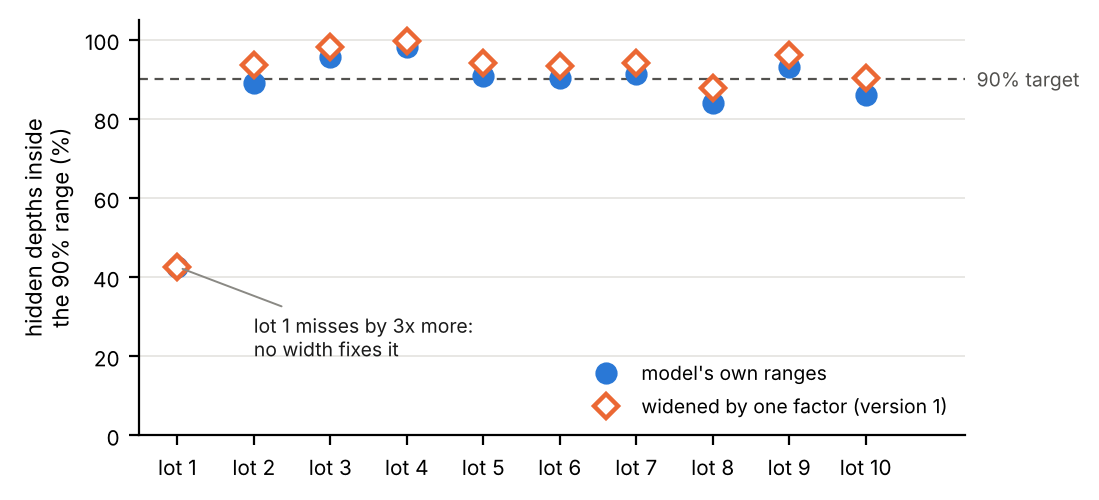

In [18]:
# Figure 1: lot by lot, the model's own ranges against one widening factor (5 random sites)
fig, ax = plt.subplots(figsize=(5.6, 2.6))
ax.axhline(90, color='#52514e', lw=0.8, ls=(0, (4, 3)))
ax.text(10.45, 90, '90% target', fontsize=7, color='#52514e', va='center')
x = np.arange(len(lots))
ax.plot(x, 100 * cov_lot['own'], 'o', ms=7, color='#2a78d6', label="model's own ranges")
ax.plot(x, 100 * cov_lot['version 1'], 'D', ms=6, mfc='white', mec='#eb6834', mew=1.6, label='widened by one factor (version 1)')
ax.set_xticks(x)
ax.set_xticklabels(['lot %d' % L for L in lots], fontsize=7.5)
ax.set_ylabel('hidden depths inside\nthe 90% range (%)', fontsize=8)
ax.set_ylim(0, 105)
ax.set_xlim(-0.5, 10.3)
ax.grid(axis='y', color='#e4e3df', lw=0.6)
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(labelsize=7.5)
ax.annotate('lot 1 misses by 3x more:\nno width fixes it', (0, 100 * cov_lot['own'][0]), (1.0, 20), fontsize=7,
            color='#1a1a1a', arrowprops=dict(arrowstyle='-', color='#8a8984', lw=0.7))
ax.legend(fontsize=7, frameon=False, loc='lower right')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'part3_coverage.png'), dpi=220, bbox_inches='tight')
plt.show()

## 6. The input check's threshold depends on how many sites are measured
The check drops the worst reading if its leave-one-out z exceeds a threshold. Part 2 used 6 for every
number of sites. Here the threshold is set on the training lots of each fold so that it questions a
good reading on 1% of clean wafers.

In [19]:
thr = pd.DataFrame({L: {k: PREP[L]['T'][k] for k in KS_CHECK} for L in lots})
print('Check threshold (leave-one-out z) by number of sites: median over folds, and the fold without lot 1')
print(pd.DataFrame({'median': thr.median(axis=1), 'lot 1 held out': thr[1]}).T.round(1).to_string())
print()
for group, k in [('random', 3), ('random', 5), ('random', 9), ('random', 13), ('random', 20),
                 ('routine', 'routine 9'), ('chosen', 5), ('chosen', 9)]:
    a = lambda q, f: sum(RES[L].get((group, k, q, f, 0), np.zeros(2))[0] for L in lots)
    clean_lot = np.array([RES[L].get((group, k, 'alarm', 'clean', 0), np.zeros(2))[0] /
                          RES[L].get((group, k, 'wafers', 'clean', 0), np.ones(2))[0] for L in lots])
    other = (sum(RES[L].get((group, k, 'alarm', 'clean', 0), np.zeros(2))[0] for L in lots[1:]) /
             sum(RES[L].get((group, k, 'wafers', 'clean', 0), np.zeros(2))[0] for L in lots[1:]))
    print('%-8s %-9s suspect reading measured %3d times, dropped %3d | good reading questioned on %.1f%% of clean wafers '
          '(lot 1: %.0f%%, lots 2-10: %.1f%%, highest of those lots %.1f%%)'
          % (group, k, a('wafers', 'suspect'), a('alarm', 'suspect'), 100 * a('alarm', 'clean') / a('wafers', 'clean'),
             100 * clean_lot[0], 100 * other, 100 * clean_lot[1:].max()))

Check threshold (leave-one-out z) by number of sites: median over folds, and the fold without lot 1
                 2    3    4    5    6    7    8    9    10   11   12    13    14    15    16    17    18    19    20
median          5.3  7.6  7.5  8.1  7.5  8.4  7.9  7.8  8.5  9.7  8.4  10.9  10.3  10.8  11.8  11.7  10.5  12.5  12.0
lot 1 held out  3.4  4.0  4.2  5.7  6.2  7.5  7.0  7.5  8.3  9.9  8.7  10.9  10.1  10.8  11.9  11.7  10.4  12.6  12.0

random   3         suspect reading measured  16 times, dropped  16 | good reading questioned on 5.7% of clean wafers (lot 1: 55%, lots 2-10: 0.1%, highest of those lots 1.4%)
random   5         suspect reading measured  18 times, dropped  18 | good reading questioned on 3.3% of clean wafers (lot 1: 31%, lots 2-10: 0.2%, highest of those lots 1.5%)
random   9         suspect reading measured  35 times, dropped  35 | good reading questioned on 0.8% of clean wafers (lot 1: 1%, lots 2-10: 0.8%, highest of those lots 4.1%)
random   13        su

In [20]:
# With all 89 sites measured: part 2's fixed threshold of 6 against a threshold set for 89 sites
# (the 99th percentile of the largest z on the inner split, as above)
alarms6 = alarms_k = 0
T89 = []
for L in lots:
    Ytr, lM, pM = TRAIN[L]
    m = PREP[L]['m']
    zin = []
    for l in np.unique(lM):                                        # inner split, all 89 sites measured
        o = lM != l
        zin += list(surprise(learn_model(Ytr[o], pM[o], m['cfg']), np.arange(89), Ytr[~o], pM[~o])[0].max(axis=1))
    T89.append(np.quantile(zin, 1 - CHECK_RATE))
    te = np.where(lot == L)[0]
    ok = valid[te].all(axis=1)                                     # wafers without a suspect reading
    zt = surprise(m, np.arange(89), Y[te], pos[te])[0].max(axis=1)[ok]
    alarms6 += (zt > 6).sum()
    alarms_k += (zt > T89[-1]).sum()
print('89 sites: threshold %.1f (median over folds) | false alarms on the 86 clean wafers: %d with 6, %d with the 89-site threshold'
      % (np.median(T89), alarms6, alarms_k))

89 sites: threshold 29.6 (median over folds) | false alarms on the 86 clean wafers: 15 with 6, 0 with the 89-site threshold


- **The threshold rises with the number of sites**: about 8 at 3 to 10 sites, 11 at 13, 12 at 20 and
  30 with all 89, because more readings give more chances for one to look odd. With all 89 sites a
  fixed 6 questions a good reading on 15 of the 86 clean wafers; the 89-site threshold on none.
- **Every suspect reading that was measured was caught**, at every number of sites.
- **The good readings it questions are mostly lot 1's** with few sites (with 5 chosen sites, 8 of its
  9 wafers). On lots 2 to 10 the rate stays near the 1% target. In lot 1 the readings disagree with
  each other because the wafer is unusual, not because one reading is bad. Part 2's policy handles
  that: re-measure the questioned site; if the repeat agrees, keep the reading. Here the reading is
  simply dropped, and the flag (next section) still catches the wafer.

## 7. A flag for wafers unlike past ones
The surprise d2 compares the readings with what is usual. For a usual wafer it is about the number of
readings. It has two parts: the fitted shape amounts far from usual (*amounts*), and readings that
disagree with the fitted map (the rest, which needs more readings than unknowns). The flag fires when
d2 is above the threshold set on training lots (top 5% of training wafers, for that number of readings).

In [21]:
for group, k in [('chosen', 5), ('chosen', 9), ('routine', 'routine 9'), ('chosen', 13)]:
    s = REC[(REC.group == group) & (REC.k == k)]
    per = s.groupby('lot').flagged.agg(['sum', 'count'])
    print('%-8s %-9s flagged per lot: %s' % (group, k, '  '.join('%d/%d' % (a, b) for a, b in per.values)))
s5 = REC[(REC.group == 'chosen') & (REC.k == 5)]
print('\nRandom layouts, share of wafers flagged:')
for k in [3, 5, 9, 13]:
    rate = total('random', k, 'flagged', 'all', per_lot=True)
    print('  %2d sites: lot 1 %.0f%%, lots 2-10 %.1f%% (highest lot %.1f%%)' % (k, 100 * rate[0], 100 * total('random', k, 'flagged', 'all', lots_sel=lots[1:]), 100 * rate[1:].max()))
print('\nThe two cases, 5 chosen sites:')
print(s5[s5.lot.isin([1, 8])][['lot', 'wafer', 'kept', 'd2', 'amounts', 'threshold', 'flagged', 'cover']].round(2).to_string(index=False))

chosen   5         flagged per lot: 7/9  0/10  0/10  0/10  0/10  0/10  0/6  2/10  0/9  0/4
chosen   9         flagged per lot: 8/9  0/10  0/10  0/10  0/10  0/10  0/6  1/10  0/9  0/4
routine  routine 9 flagged per lot: 9/9  0/10  0/10  0/10  0/10  0/10  0/6  0/10  0/9  0/4
chosen   13        flagged per lot: 7/9  0/10  0/10  0/10  0/10  0/10  0/6  1/10  0/9  0/4

Random layouts, share of wafers flagged:
   3 sites: lot 1 41%, lots 2-10 0.2% (highest lot 1.2%)
   5 sites: lot 1 82%, lots 2-10 0.2% (highest lot 0.7%)
   9 sites: lot 1 87%, lots 2-10 0.3% (highest lot 1.7%)
  13 sites: lot 1 76%, lots 2-10 0.8% (highest lot 3.5%)

The two cases, 5 chosen sites:
 lot  wafer  kept    d2  amounts  threshold  flagged  cover
   1      1     4 33.69    31.47      11.93        1   0.18
   1      2     4 12.75    11.83      11.93        1   0.15
   1      3     4 30.35    27.69      11.93        1   0.17
   1      4     4 13.85    13.19      11.93        1   0.11
   1      5     4 10.38     9.02  

- **Lot 1 is flagged**: 7 of 9 wafers with 5 chosen sites, 8 of 9 with 9 chosen sites, 9 of 9 with
  the routine 9. Almost all of its surprise is in the amounts (its tilt), not in readings that disagree.
- **Lot 8 wafers 8 and 9 are flagged with 5 chosen sites**, and no other wafer of lots 2 to 10.
  They are the two wafers that broke the lot's drift. Half of their surprise is in the amounts.
  With 9 chosen sites one of them passes, and with the routine 9 both do.
- **False alarms are below the 5% target** on lots 2 to 10: lot 1 sits in the training lots of
  every other fold and its wafers set the threshold. So the flag catches wafers about as unusual as
  lot 1. The table below shows the trade-off if the threshold were set lower.

In [22]:
print('Threshold at other percentiles of the training wafers (5 chosen sites):')
for q in [0.80, 0.85, 0.90, 0.95, 0.99]:
    f = np.array([d2 > PREP[L]['TFq'][kept][q] for L, kept, d2 in zip(s5.lot, s5.kept, s5.d2)])
    l8 = ((s5.lot == 8) & s5.wafer.isin([8, 9])).to_numpy()
    rest = (s5.lot != 1).to_numpy() & ~l8
    print('  top %2d%%: lot 1 %d/9, lot 8 wafers 8-9 %d/2, other wafers %d/%d'
          % (round(100 * (1 - q)), f[(s5.lot == 1).to_numpy()].sum(), f[l8].sum(), f[rest].sum(), rest.sum()))
# What more sites buy on the wafers flagged at 5 chosen sites
flagged5 = s5[s5.flagged == 1][['lot', 'wafer']]
print('\nWafers flagged at 5 chosen sites (%d), measured at more chosen sites:' % len(flagged5))
for k in [5, 9, 13, 20]:
    t = REC[(REC.group == 'chosen') & (REC.k == k)].merge(flagged5, on=['lot', 'wafer'])
    u = REC[(REC.group == 'chosen') & (REC.k == k)].merge(flagged5, on=['lot', 'wafer'], how='left', indicator=True)
    u = u[u._merge == 'left_only']
    print('  %2d sites: error %.3f µm (edge %.3f), ranges hold %.0f%% | the other wafers: %.3f µm, %.0f%%'
          % (k, np.sqrt(t.sse.sum() / t.n.sum()), np.sqrt(t.sse_edge.sum() / t.n_edge.sum()),
             100 * np.average(t.cover, weights=t.n), np.sqrt(u.sse.sum() / u.n.sum()), 100 * np.average(u.cover, weights=u.n)))

Threshold at other percentiles of the training wafers (5 chosen sites):
  top 20%: lot 1 9/9, lot 8 wafers 8-9 2/2, other wafers 6/77
  top 15%: lot 1 9/9, lot 8 wafers 8-9 2/2, other wafers 2/77
  top 10%: lot 1 8/9, lot 8 wafers 8-9 2/2, other wafers 0/77
  top  5%: lot 1 7/9, lot 8 wafers 8-9 2/2, other wafers 0/77
  top  1%: lot 1 2/9, lot 8 wafers 8-9 0/2, other wafers 0/77

Wafers flagged at 5 chosen sites (9), measured at more chosen sites:
   5 sites: error 0.170 µm (edge 0.210), ranges hold 30% | the other wafers: 0.050 µm, 91%
   9 sites: error 0.087 µm (edge 0.127), ranges hold 60% | the other wafers: 0.039 µm, 91%
  13 sites: error 0.067 µm (edge 0.094), ranges hold 54% | the other wafers: 0.038 µm, 91%
  20 sites: error 0.065 µm (edge 0.095), ranges hold 55% | the other wafers: 0.037 µm, 92%


**What extra sites buy on a flagged wafer.** Going from 5 to 9 chosen sites halves its error; 13 sites
cut it to about 40%, after which more sites add nothing. But its ranges still hold only 54–60%:
the model does not know this kind of wafer, so it cannot say how unsure it is. Only a full map makes a
flagged wafer safe. On these lots that costs 84 more sites on about 1 wafer in 10, all but two of them
in lot 1.

**A pre-measurement hint.** Every lot 1 wafer had a higher helium backside flow than any other wafer
(tool sensor logs, not used here). That was found after looking at all lots, so it is a candidate for
a flag before any depth is measured, not a tested one.

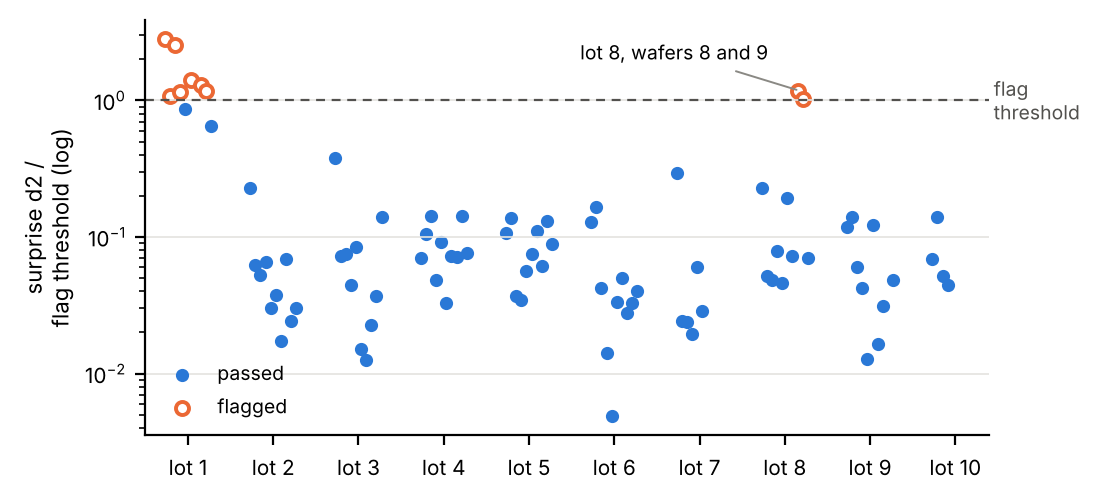

In [23]:
# Figure 2: the flag, wafer by wafer (5 chosen sites)
fig, ax = plt.subplots(figsize=(5.6, 2.6))
ratio = (s5.d2 / s5.threshold).to_numpy()
xs_ = s5.lot.to_numpy() + (s5.wafer.to_numpy() - 5.5) * 0.06
ax.axhline(1, color='#52514e', lw=0.8, ls=(0, (4, 3)))
ax.text(10.45, 1, 'flag\nthreshold', fontsize=7, color='#52514e', va='center')
ax.scatter(xs_[s5.flagged == 0], ratio[s5.flagged == 0], s=14, color='#2a78d6', label='passed')
ax.scatter(xs_[s5.flagged == 1], ratio[s5.flagged == 1], s=22, facecolor='white', edgecolor='#eb6834', lw=1.4, label='flagged')
ax.set_yscale('log')
ax.set_xticks(lots)
ax.set_xticklabels(['lot %d' % L for L in lots], fontsize=7.5)
ax.set_xlim(0.5, 10.4)
ax.set_ylabel('surprise d2 /\nflag threshold (log)', fontsize=8)
ax.annotate('lot 8, wafers 8 and 9', (8.2, ratio[((s5.lot == 8) & (s5.wafer == 8)).to_numpy()][0]), (5.6, 2.0), fontsize=7,
            arrowprops=dict(arrowstyle='-', color='#8a8984', lw=0.7))
ax.grid(axis='y', color='#e4e3df', lw=0.6, which='major')
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(labelsize=7.5)
ax.legend(fontsize=7, frameon=False, loc='lower left')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'part3_flag.png'), dpi=220, bbox_inches='tight')
plt.show()

## 8. Where to measure: chosen sites against the routine 9 and random sites
The sites are chosen one at a time on each fold's training lots (section 3), so each held-out lot is
measured at sites chosen without it. The first k chosen sites form the k-site layout.

In [24]:
from collections import Counter
print('Error at hidden sites, inner / edge (µm), held-out lots:')
print('            ours, chosen   ours, random   rival A, chosen  rival A, random  A+GP, chosen   A+GP, random')
for k in list(range(3, 14)) + [20]:
    cells = []
    for meth in ['ours', 'rival A', 'rival A+GP']:
        for group in ['chosen', 'random']:
            cells.append('%.3f / %.3f' % (rms(group, k, meth, 0), rms(group, k, meth, 1)))
    print('%2d sites   ' % k + '  '.join(cells))
print('routine 9  ' + '  '.join('%.3f / %.3f' % (rms('routine', 'routine 9', m, 0), rms('routine', 'routine 9', m, 1))
                               for m in ['ours', 'rival A', 'rival A+GP']))
print('\nAll hidden sites together (µm): routine 9 %.3f | chosen: %s'
      % (rms('routine', 'routine 9', 'ours'), '  '.join('%d: %.3f' % (k, rms('chosen', k, 'ours')) for k in range(3, 14))))
for k in [5, 7, 9]:
    pc = np.sqrt(total('chosen', k, 'ours', per_lot=True))
    pr = np.sqrt(total('routine', 'routine 9', 'ours', per_lot=True))
    pn = np.sqrt(total('random', k, 'ours', per_lot=True))
    print('%d chosen sites beat the routine 9 in %d of 10 lots and %d random sites in %d of 10 (all hidden sites)'
          % (k, (pc < pr).sum(), k, (pc < pn).sum()))

Error at hidden sites, inner / edge (µm), held-out lots:
            ours, chosen   ours, random   rival A, chosen  rival A, random  A+GP, chosen   A+GP, random
 3 sites   0.056 / 0.120  0.066 / 0.142  0.104 / 0.165  0.095 / 0.201  0.126 / 0.193  0.112 / 0.199
 4 sites   0.056 / 0.099  0.057 / 0.131  0.104 / 0.161  0.091 / 0.200  0.181 / 0.281  0.096 / 0.183
 5 sites   0.053 / 0.090  0.045 / 0.115  0.099 / 0.164  0.086 / 0.196  0.153 / 0.258  0.085 / 0.173
 6 sites   0.051 / 0.096  0.037 / 0.104  0.100 / 0.164  0.084 / 0.195  0.133 / 0.253  0.079 / 0.166
 7 sites   0.025 / 0.061  0.031 / 0.097  0.099 / 0.162  0.084 / 0.192  0.140 / 0.259  0.079 / 0.161
 8 sites   0.028 / 0.065  0.029 / 0.093  0.095 / 0.161  0.081 / 0.194  0.121 / 0.260  0.077 / 0.160
 9 sites   0.024 / 0.066  0.025 / 0.089  0.097 / 0.162  0.078 / 0.192  0.102 / 0.214  0.068 / 0.153
10 sites   0.023 / 0.066  0.024 / 0.089  0.097 / 0.163  0.079 / 0.193  0.092 / 0.190  0.062 / 0.154
11 sites   0.024 / 0.059  0.023 / 0.083

In [25]:
# Which sites are chosen, and how stable is the choice across the 10 folds?
for k in [5, 9]:
    count = Counter(int(s) for L in lots for s in PREP[L]['sites'][:k])
    sets = [set(PREP[L]['sites'][:k].tolist()) for L in lots]
    overlap = np.mean([len(a & b) / len(a | b) for i, a in enumerate(sets) for b in sets[i + 1:]])
    print('%d sites: chosen in at least 8 of 10 folds: %s | average overlap of two folds\' sets %.0f%% | inner sites per set %.1f'
          % (k, [sites[s] for s, n in count.most_common() if n >= 8], 100 * overlap, np.mean([inner[PREP[L]['sites'][:k]].sum() for L in lots])))
print('Order chosen in the fold that holds out lot 2:', [sites[s] for s in PREP[2]['sites'][:9]])

5 sites: chosen in at least 8 of 10 folds: [(19, 76), (-95, 19), (-95, 0)] | average overlap of two folds' sets 58% | inner sites per set 1.7
9 sites: chosen in at least 8 of 10 folds: [(19, 76), (-95, 19), (95, 19), (-76, -38), (-95, 0), (-38, -19)] | average overlap of two folds' sets 52% | inner sites per set 2.8
Order chosen in the fold that holds out lot 2: [(19, 76), (-76, -19), (-95, 0), (-95, 19), (57, -19), (-76, -38), (95, 19), (-38, -19), (57, 57)]


**What this shows.**
- **Chosen sites go to the edge**: about 2 of the first 5 and 3 of the first 9 are inner sites. The
  edge is where wafers differ most, so that is where a reading tells the model most.
- **5 chosen sites match the routine 9** on all hidden sites together (0.072 against 0.071 µm). They
  beat it at the edge (0.090 against 0.099 µm) and lose inside (0.053 against 0.018 µm), and they beat
  it in 9 of 10 lots; lot 1 is the exception.
- **7 chosen sites beat the routine 9 everywhere except inside** (0.044 µm on all hidden sites, edge
  0.061). The curve is not smooth: 6 and 8 to 10 sites do slightly worse than 7. The chosen order comes
  from predicted error, and with 10 lots the real error is noisy.
- **Is the gain from the shapes or from the sites?** Both. At 5 sites and at the edge, choosing the
  sites takes the model from 0.115 to 0.090 µm; on the same chosen sites the shifted average map
  (rival A) misses by 0.164 µm. The sites chosen for the model help rival A at the edge too (0.196 to
  0.164), but less. Rival A+GP does worse on them than on random sites: they cluster at the edge, so a
  smooth surface through them extrapolates badly inward.
- **The choice is fairly stable.** Three sites, (19, 76), (−95, 19) and (−95, 0), are among the first 5
  in 9 or 10 folds. Two folds' 5-site sets share about 58% of their sites.

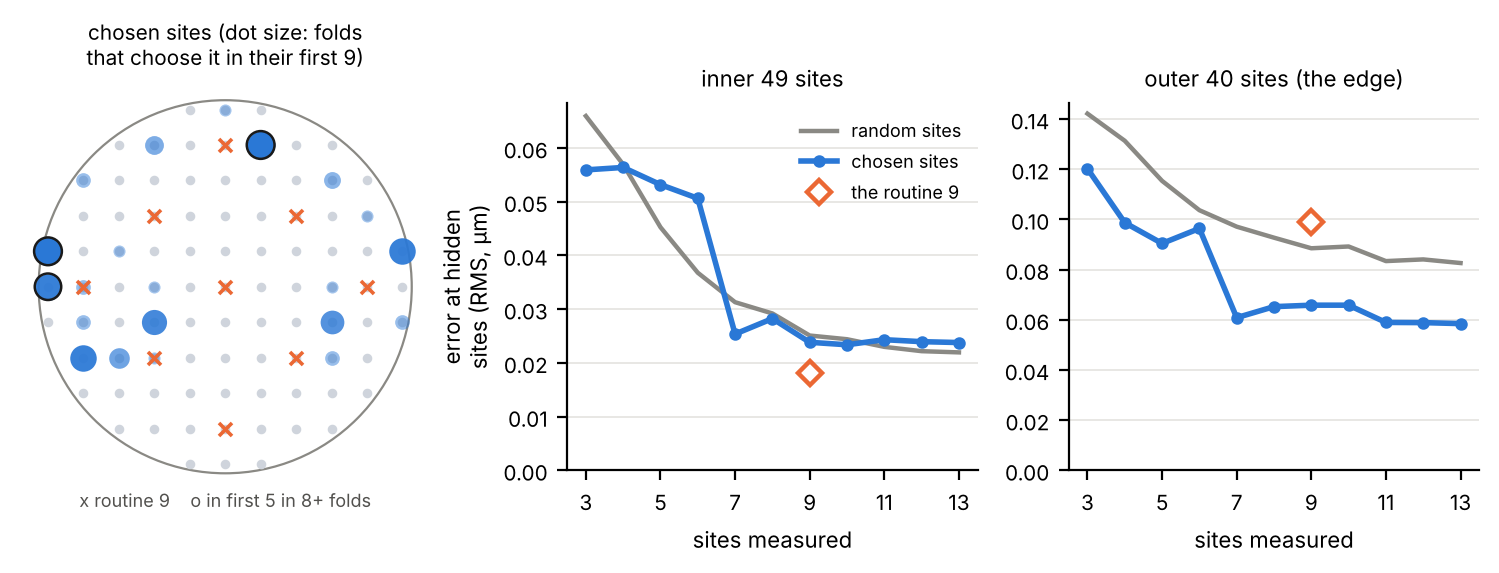

In [26]:
# Figure 3: the chosen sites on the wafer, and error against the number of sites
fig = plt.figure(figsize=(7.6, 2.7))
ax0 = fig.add_axes([0.0, 0.12, 0.27, 0.78])
count9 = Counter(int(s) for L in lots for s in PREP[L]['sites'][:9])
count5 = Counter(int(s) for L in lots for s in PREP[L]['sites'][:5])
ax0.add_patch(plt.Circle((0, 0), 100, fill=False, color='#8a8984', lw=0.8))
ax0.scatter(xy[:, 0], xy[:, 1], s=6, color='#cfd4dc')
for s, n in count9.items():
    ax0.scatter(*xy[s], s=10 + 9 * n, color='#2a78d6', alpha=0.35 + 0.065 * n, lw=0)
for s, n in count5.items():
    if n >= 8:
        ax0.scatter(*xy[s], s=10 + 9 * n, facecolor='none', edgecolor='#1a1a1a', lw=0.9)
ax0.scatter(xy[routine, 0], xy[routine, 1], marker='x', s=22, color='#eb6834', lw=1.3)
ax0.set_aspect('equal'); ax0.axis('off')
ax0.set_title('chosen sites (dot size: folds\nthat choose it in their first 9)', fontsize=7.5)
ax0.text(0, -118, 'x routine 9    o in first 5 in 8+ folds', fontsize=6.5, ha='center', color='#52514e')
for j, (g, title) in enumerate([(0, 'inner 49 sites'), (1, 'outer 40 sites (the edge)')]):
    ax = fig.add_axes([0.36 + j * 0.33, 0.17, 0.27, 0.68])
    kk = list(range(3, 14))
    ax.plot(kk, [rms('random', k, 'ours', g) for k in kk], '-', color='#8a8984', lw=1.6, label='random sites')
    ax.plot(kk, [rms('chosen', k, 'ours', g) for k in kk], '-o', color='#2a78d6', lw=2, ms=3.5, label='chosen sites')
    ax.plot(9, rms('routine', 'routine 9', 'ours', g), 'D', ms=6, mfc='white', mec='#eb6834', mew=1.6, label='the routine 9')
    ax.set_title(title, fontsize=8)
    ax.set_xlabel('sites measured', fontsize=8)
    ax.set_ylim(0, None)
    ax.set_xticks([3, 5, 7, 9, 11, 13])
    ax.grid(axis='y', color='#e4e3df', lw=0.6)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(labelsize=7.5)
    if j == 0:
        ax.set_ylabel('error at hidden\nsites (RMS, µm)', fontsize=8)
        ax.legend(fontsize=6.5, frameon=False)
fig.savefig(os.path.join(FIG_DIR, 'part3_sites.png'), dpi=220, bbox_inches='tight')
plt.show()

## 9. Side check: many inner readings
Part 1 found that fitting all 49 inner sites predicted the edge worse than the routine 9 (0.141 against
0.109 µm), probably because the model treated neighbouring leftovers as independent and over-trusted
many inner readings. The versions of section 1 on that case (held-out lots, clean readings):

In [27]:
inner_sites = np.where(inner)[0]
side = {}
for L in lots:
    Ytr, lM, pM = TRAIN[L]
    te = np.where(lot == L)[0]
    for name, cfg in [('part 1 model', PART1), ('full prior, 5 shapes', dict(PART1, K=5, prior='full')),
                      ('full prior, 5 shapes, correlated leftover', dict(PART1, K=5, prior='full', leftover='correlated'))]:
        m = learn_model(Ytr, pM, cfg)
        for lay, idx in [('49 inner', inner_sites), ('routine 9', np.array(routine))]:
            p, sd = predict(m, idx, Y[te][:, idx], pos[te])
            h = (~inner)[None, :] & valid[te]
            a = side.setdefault((name, lay), np.zeros(3))
            a += [((p - Y[te]) ** 2)[h].sum(), h.sum(), (np.abs(p - Y[te]) <= 1.645 * sd)[h].sum()]
for (name, lay), a in side.items():
    print('%-42s from %-9s: edge error %.3f µm, own ranges hold %.0f%%' % (name, lay, np.sqrt(a[0] / a[1]), 100 * a[2] / a[1]))

part 1 model                               from 49 inner : edge error 0.141 µm, own ranges hold 78%
part 1 model                               from routine 9: edge error 0.109 µm, own ranges hold 86%
full prior, 5 shapes                       from 49 inner : edge error 0.114 µm, own ranges hold 79%
full prior, 5 shapes                       from routine 9: edge error 0.097 µm, own ranges hold 88%
full prior, 5 shapes, correlated leftover  from 49 inner : edge error 0.106 µm, own ranges hold 84%
full prior, 5 shapes, correlated leftover  from routine 9: edge error 0.097 µm, own ranges hold 88%


The full prior removes most of the problem (0.141 to 0.114 µm), and the correlated leftover a bit more
(0.106), with better-calibrated ranges. The routine 9 still predict the edge better than all 49 inner
sites. This case is not a realistic plan, so it does not change the choice of section 2; it says that
if a plan ever measures many sites close together, the correlated leftover should come back.

## 10. Summary of part 3
- **The model:** chosen on training lots, a full prior (level and shapes move together) and 5 shapes.
  Position in the lot adds nothing once the prior is full. Error at 5 random sites drops from
  0.053 / 0.126 µm (part 2) to 0.045 / 0.115 (inner / edge).
- **Ranges:** part 2's 86% was mostly lot 1 (43%); the other lots held 91%. One widening factor set on
  training lots brings held-out coverage to about 90%, but by making every range 21% wider, and lot 1
  stays below 45%. Version 2 is no better. Used instead: ranges widened by a factor learned on training
  wafers the flag passes (about 1.1). On wafers the flag passes they hold 89–94%.
- **Input check:** its threshold rises with the number of sites (about 8 at 5 sites, 11 at 13, 30 at 89).
  It caught every suspect reading; good readings questioned stay near 1% outside lot 1.
- **Flag:** catches 7 to 9 of lot 1's 9 wafers, and lot 8's two drift-breaking wafers at 5 chosen
  sites, with no false alarm on the other 77 wafers. A flagged wafer needs a full map.
- **Sites:** chosen sites go to the edge. 5 chosen sites match the routine 9 overall and beat it in
  9 of 10 lots; 7 beat it everywhere except inside the wafer.

**Open for part 4:** how many fully measured wafers this needs, the fewest sites for the plan, and the
same plan trained only on earlier lots.